# **Land Coverage Mapping**
*Code set A and B are internal classification done by team for ease of operation*


---


*Anushka Sarjerao Patil* [Linkedin](https://www.linkedin.com/in/anushka-patil-163286276/)

*Kartik Pandey* [Linkedin](https://www.linkedin.com/in/pandeykartik/)

*Narsimha Siddharth* [Linkedin](https://www.linkedin.com/in/narasimha-siddharth-amirapu-%E2%A0%80-9b9a27343/)

*Dr. Ceronmani Sharmila* [Organisation Page](https://www.srmist.edu.in/faculty/ceronmani-sharmila-v/)


In [ ]:
FILE_PATH = "/content/GeoXNet_Nanded_Test.csv"

In [ ]:
%pip install catboost
%pip install tensorflow
%pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.6 MB/s eta 0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving GeoXNet_Nanded_Balanced.csv to GeoXNet_Nanded_Balanced (1).csv


In [ ]:
import os

filename = next(
    name for name in uploaded
    if name.endswith(".csv")
)

CFG["FILE_PATH"] = "/content/" + filename

df = pd.read_csv(CFG["FILE_PATH"])
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (4000, 14)
           B2          B3          B4      B5           B6           B7  \
0  394.500000  573.500000  402.500000  421.00   284.500000   276.000000   
1  289.000000  538.500000  313.500000  385.50   158.000000   146.500000   
2  530.000000  759.000000  854.000000  997.00  1051.000000  1140.000000   
3  525.333333  788.000000  570.000000  747.25   507.250000   520.750000   
4  463.600000  778.666667  573.333333  883.25   526.666667   560.333333   

            B8     B8A     B11         B12      NDVI      NDWI      NDBI  \
0   162.000000   220.0   189.5  151.500000 -0.426041  0.559483  0.078236   
1   100.500000    88.5   152.5  146.000000 -0.514493  0.685446  0.205534   
2  1001.000000  1145.0  1102.0  831.000000  0.079245 -0.137500  0.048027   
3   444.333333   393.8   243.0  142.500000 -0.123891  0.278875 -0.292919   
4   463.000000   448.5   275.4  184.333333 -0.106465  0.254228 -0.254063   

   landcover  
0          1  
1          1  
2          1  
3     

# ***Code Set B***

shape: (4000, 14)
columns: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI', 'landcover']
dtypes:
 B2           float64
B3           float64
B4           float64
B5           float64
B6           float64
B7           float64
B8           float64
B8A          float64
B11          float64
B12          float64
NDVI         float64
NDWI         float64
NDBI         float64
landcover      int64
other columns (ignored): []
missing values:
 B2           0
B3           0
B4           0
B5           0
B6           0
B7           0
B8           0
B8A          0
B11          0
B12          0
NDVI         0
NDWI         0
NDBI         0
landcover    0
coordinate-like columns present: NONE -> spatial split is impossible
duplicate rows dropped: 2

class distribution (original labels):
 landcover
1    1000
2    1000
3     998
4    1000
train 2398 | val 600 | test 1000


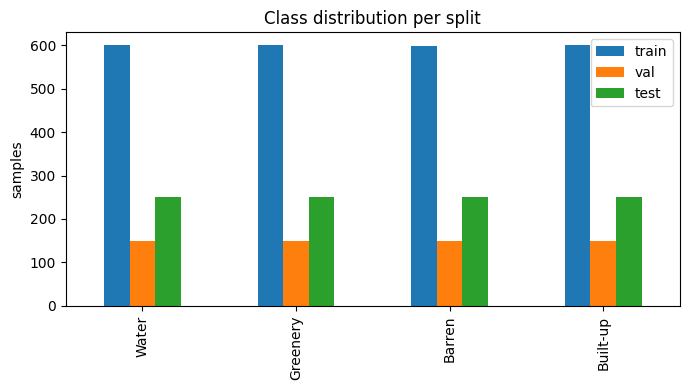

Random Forest                acc=0.9420  macroF1=0.9422  kappa=0.9227  train=4.6s
CatBoost                     acc=0.9480  macroF1=0.9483  kappa=0.9307  train=15.5s

##### ResNet-1D
trained 24 epochs, 106,276 params
ResNet-1D                    acc=0.9410  macroF1=0.9414  kappa=0.9213  train=24.8s
Random Forest + ResNet-1D    acc=0.9470  macroF1=0.9472  kappa=0.9293  train=28.4s
CatBoost + ResNet-1D         acc=0.9480  macroF1=0.9483  kappa=0.9307  train=34.5s

##### EfficientNet-1D
trained 20 epochs, 79,464 params
EfficientNet-1D              acc=0.9430  macroF1=0.9433  kappa=0.9240  train=38.8s


CatBoost + EfficientNet-1D   acc=0.9500  macroF1=0.9503  kappa=0.9333  train=55.6s

=== TEST RESULTS (real) | test samples = 1000 ===
                             Accuracy  Precision  Recall      F1   Kappa  TrainTime  InferTime  InferMs_per_sample
Model                                                                                                            
Random Forest                  0.942     0.9430   0.942  0.9422  0.9227     4.6315     0.1215              0.1215
CatBoost                       0.948     0.9490   0.948  0.9483  0.9307    15.4700     0.0050              0.0050
ResNet-1D                      0.941     0.9427   0.941  0.9414  0.9213    24.8412     0.5711              0.5711
EfficientNet-1D                0.943     0.9436   0.943  0.9433  0.9240    38.8477     5.1775              5.1775
Random Forest + ResNet-1D      0.947     0.9475   0.947  0.9472  0.9293    28.3934     0.3477              0.3477
CatBoost + ResNet-1D           0.948     0.9488   0.948  0.9483  0.

<Figure size 640x480 with 0 Axes>

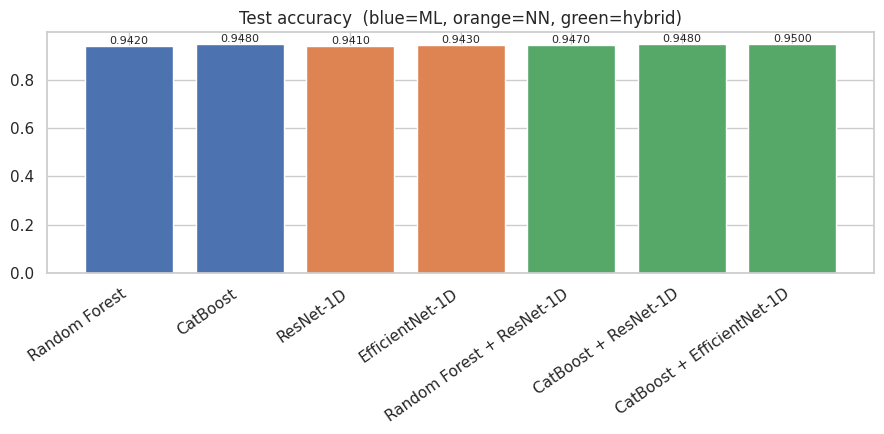

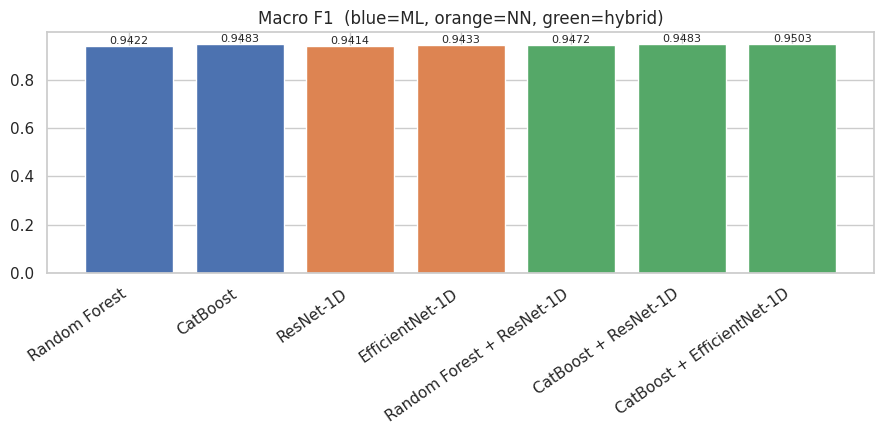

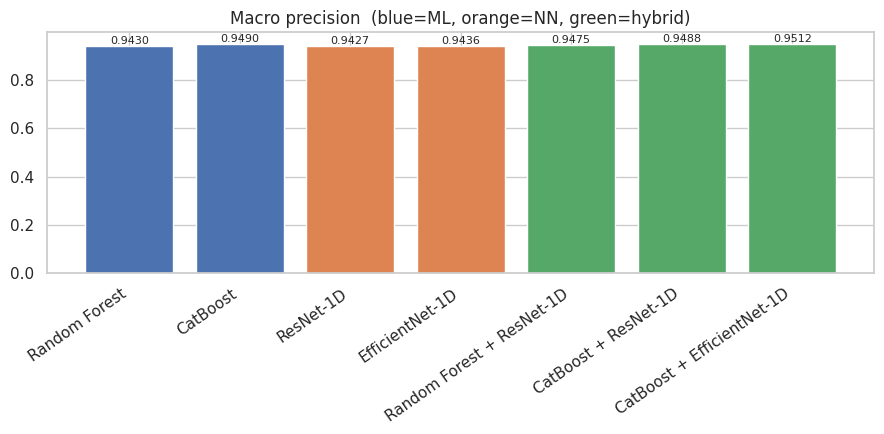

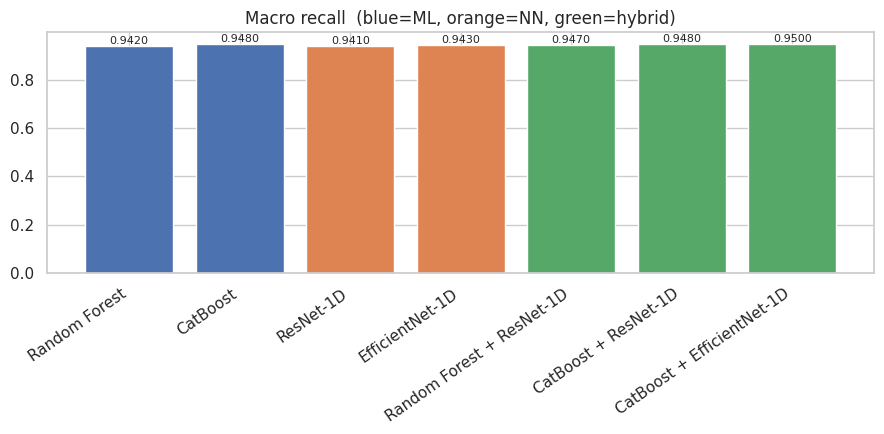

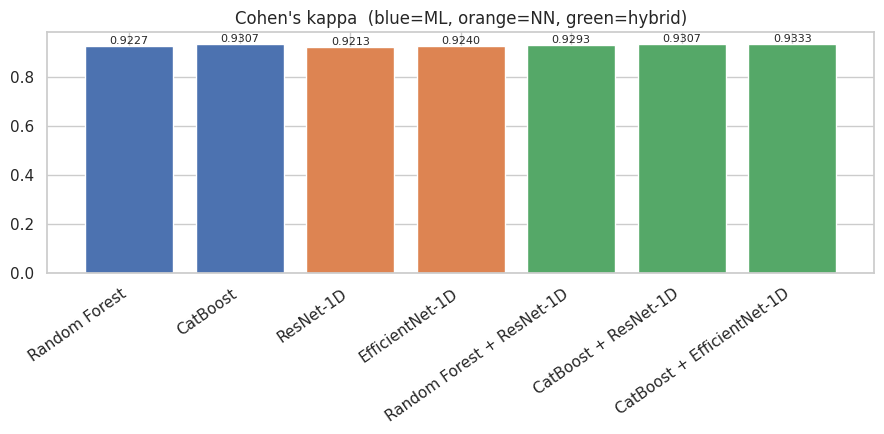

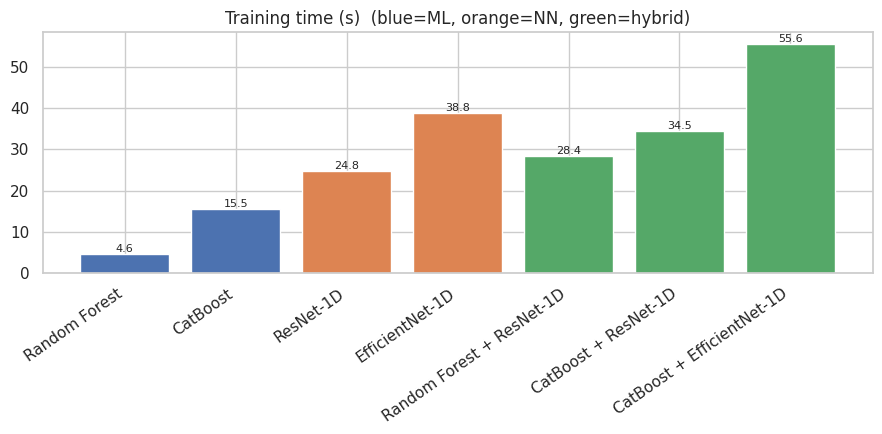

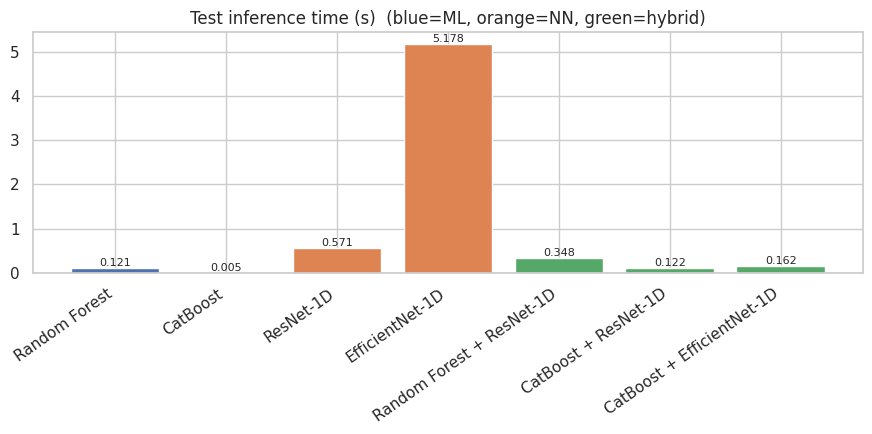

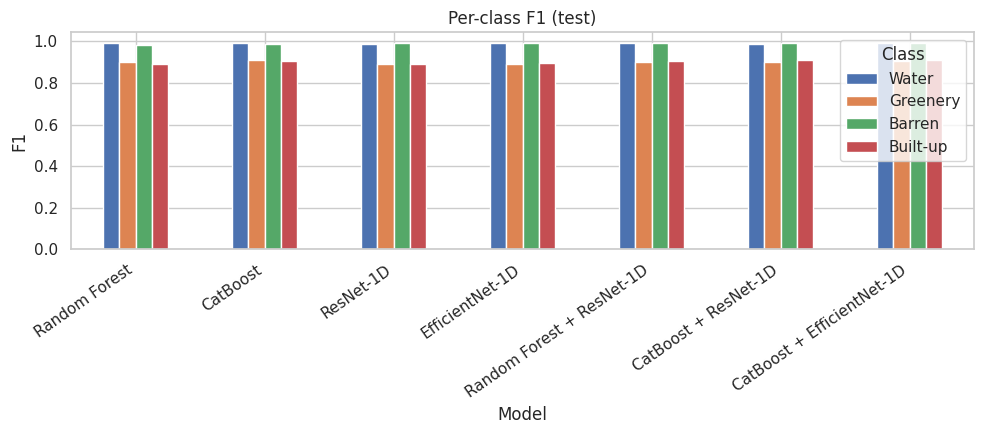

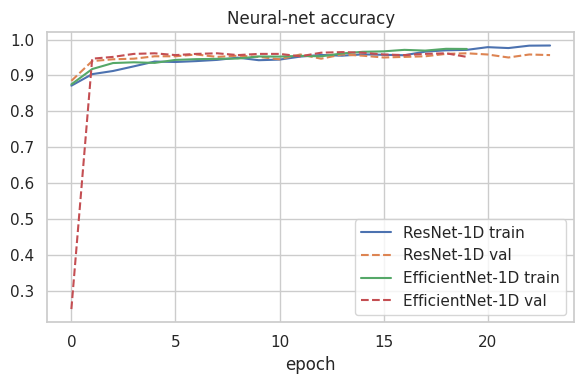

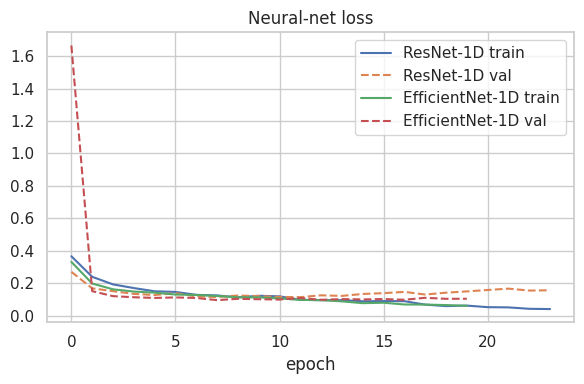

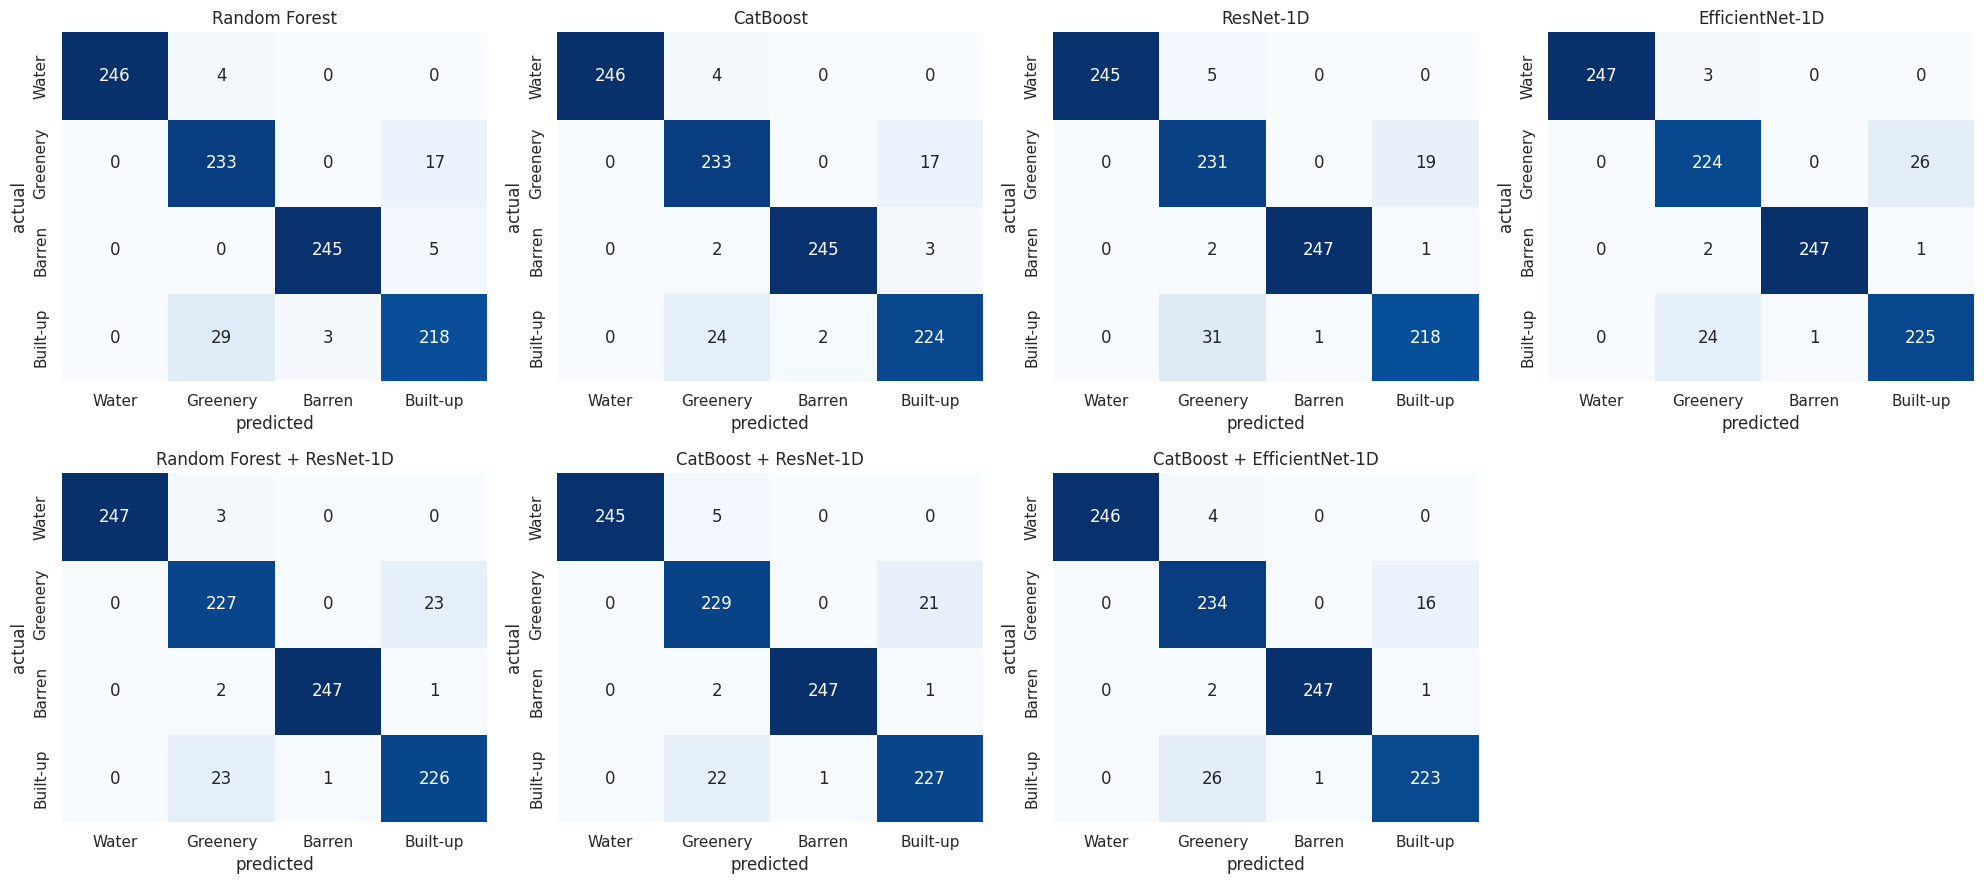

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =====================================================================
# GeoXNet Nanded (tabular Sentinel-2 pixels) -- 7 models, same split, real metrics
#   Random Forest | CatBoost | ResNet-1D | EfficientNet-1D
#   Random Forest + ResNet-1D | CatBoost + ResNet-1D | CatBoost + EfficientNet-1D
# IMPORTANT: the CSV has only per-pixel band values (no coordinates, no image patches),
# so "ResNet" / "EfficientNet" here are 1D spectral networks (ResNet-style / EfficientNet-style
# MBConv blocks) trained from scratch -- NOT the 2D ImageNet ResNet50 / EfficientNetB0.
# Run cell by cell in Colab (GPU optional). Cells are separated by "# %%".
# =====================================================================

# %% [1] Install + imports + config
# !pip -q install catboost seaborn
import os, time, json, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, cohen_kappa_score,
                             classification_report, confusion_matrix)
from catboost import CatBoostClassifier
import tensorflow as tf
from tensorflow.keras import layers, Model
warnings.filterwarnings("ignore")

CFG = dict(
    FILE_PATH="/content/GeoXNet_Nanded_Test.csv",   # upload the CSV to Colab (or mount Drive)
    OUT="/content/outputs", SEED=42,
    FEATURES=["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12", "NDVI", "NDWI", "NDBI"],
    TARGET="landcover",
    CLASS_NAMES={1: "Water", 2: "Greenery", 3: "Barren", 4: "Built-up"},   # same mapping as your XGBoost sample
    TEST_SIZE=0.25, VAL_FRAC=0.15,        # val = 15% of all data, taken from the training part
    DROP_DUPLICATES=True,                 # exact duplicate rows would leak between train and test
    EPOCHS=80, BATCH=64, LR=1e-3, FEAT_DIM=64, N_BOOT=300,
)
os.makedirs(CFG["OUT"], exist_ok=True)
np.random.seed(CFG["SEED"]); tf.random.set_seed(CFG["SEED"])

# %% [2] Load + inspect + clean
df = pd.read_csv(CFG["FILE_PATH"])
print("shape:", df.shape); print("columns:", list(df.columns)); print("dtypes:\n", df.dtypes.to_string())
miss = [c for c in CFG["FEATURES"] + [CFG["TARGET"]] if c not in df.columns]
assert not miss, f"Missing columns: {miss}"
extra = [c for c in df.columns if c not in CFG["FEATURES"] + [CFG["TARGET"]]]
print("other columns (ignored):", extra)
print("missing values:\n", df[CFG["FEATURES"] + [CFG["TARGET"]]].isna().sum().to_string())
print("coordinate-like columns present:", [c for c in df.columns if c.lower() in ("lat", "lon", "latitude", "longitude", "x", "y", "geometry")] or "NONE -> spatial split is impossible")

X = df[CFG["FEATURES"]].apply(pd.to_numeric, errors="coerce"); y = pd.to_numeric(df[CFG["TARGET"]], errors="coerce")
valid = X.notna().all(axis=1) & y.notna(); X, y = X.loc[valid], y.loc[valid].astype(int)
if CFG["DROP_DUPLICATES"]:
    d = pd.concat([X, y], axis=1).duplicated(); print("duplicate rows dropped:", int(d.sum())); X, y = X[~d], y[~d]
print("\nclass distribution (original labels):\n", y.value_counts().sort_index().to_string())
assert set(y.unique()) <= set(CFG["CLASS_NAMES"]), "unexpected label values"
CLASSES = [CFG["CLASS_NAMES"][k] for k in sorted(CFG["CLASS_NAMES"])]; yv = (y - 1).values; Xv = X.values.astype(np.float32)

# %% [3] Split (stratified random -- no coordinates exist, so NOT spatially independent)
Xtr0, Xte, ytr0, yte = train_test_split(Xv, yv, test_size=CFG["TEST_SIZE"], random_state=CFG["SEED"], stratify=yv)
Xtr, Xva, ytr, yva = train_test_split(Xtr0, ytr0, test_size=CFG["VAL_FRAC"] / (1 - CFG["TEST_SIZE"]),
                                      random_state=CFG["SEED"], stratify=ytr0)
print(f"train {len(Xtr)} | val {len(Xva)} | test {len(Xte)}")
sc = StandardScaler().fit(Xtr)                                   # scaler fitted on TRAIN only (used by the neural nets)
S = lambda a: sc.transform(a).astype(np.float32)[..., None]      # (N, 13, 1) sequence for Conv1D
pd.DataFrame({n: np.bincount(v, minlength=4) for n, v in [("train", ytr), ("val", yva), ("test", yte)]}, index=CLASSES)\
  .plot.bar(figsize=(7, 4), title="Class distribution per split"); plt.ylabel("samples"); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/fig01_class_distribution.png", dpi=200); plt.show()

# %% [4] Helpers
def metrics(yt, yp):
    p, r, f, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    return dict(Accuracy=accuracy_score(yt, yp), Precision=p, Recall=r, F1=f, Kappa=cohen_kappa_score(yt, yp),
                CM=confusion_matrix(yt, yp, labels=range(4)),
                report=classification_report(yt, yp, labels=range(4), target_names=CLASSES, zero_division=0, output_dict=True))

def fit_rf(Xa, ya, Xb, yb):
    m = RandomForestClassifier(300, n_jobs=-1, class_weight="balanced_subsample", random_state=CFG["SEED"])
    t = time.time(); m.fit(Xa, ya); return m, time.time() - t

def fit_cat(Xa, ya, Xb, yb):
    m = CatBoostClassifier(iterations=600, learning_rate=0.08, depth=6, loss_function="MultiClass",
                           auto_class_weights="Balanced", random_seed=CFG["SEED"], verbose=0, early_stopping_rounds=40)
    t = time.time(); m.fit(Xa, ya, eval_set=(Xb, yb)); return m, time.time() - t

def predict(m, A):
    t = time.time(); p = np.asarray(m.predict(A)).ravel().astype(int); return p, time.time() - t

# 1D ResNet: residual Conv1D blocks over the 13 spectral/index positions
def res_block(x, f):
    s = x
    h = layers.Conv1D(f, 3, padding="same", use_bias=False)(x); h = layers.BatchNormalization(momentum=0.9)(h); h = layers.ReLU()(h)
    h = layers.Conv1D(f, 3, padding="same", use_bias=False)(h); h = layers.BatchNormalization(momentum=0.9)(h)
    if s.shape[-1] != f: s = layers.Conv1D(f, 1, use_bias=False)(s)
    return layers.ReLU()(layers.Add()([h, s]))

def build_resnet1d(n_feat):
    i = layers.Input((n_feat, 1)); x = layers.Conv1D(32, 3, padding="same", use_bias=False)(i)
    x = layers.ReLU()(layers.BatchNormalization(momentum=0.9)(x))
    for f in (32, 64, 64): x = res_block(x, f)
    return i, layers.Flatten()(x)

# 1D EfficientNet-style: MBConv (expand -> depthwise -> squeeze-excite -> project) with swish
def mbconv(x, out, exp=4, k=3):
    c = x.shape[-1]; e = c * exp
    h = layers.Conv1D(e, 1, use_bias=False)(x); h = layers.Activation("swish")(layers.BatchNormalization(momentum=0.9)(h))
    h = layers.DepthwiseConv1D(k, padding="same", use_bias=False)(h); h = layers.Activation("swish")(layers.BatchNormalization(momentum=0.9)(h))
    se = layers.GlobalAveragePooling1D()(h); se = layers.Dense(max(2, c // 4), activation="swish")(se)
    se = layers.Dense(e, activation="sigmoid")(se); h = layers.Multiply()([h, layers.Reshape((1, e))(se)])
    h = layers.BatchNormalization(momentum=0.9)(layers.Conv1D(out, 1, use_bias=False)(h))
    return layers.Add()([x, h]) if c == out else h

def build_effnet1d(n_feat):
    i = layers.Input((n_feat, 1)); x = layers.Conv1D(16, 3, padding="same", use_bias=False)(i)
    x = layers.Activation("swish")(layers.BatchNormalization(momentum=0.9)(x))
    for o in (16, 24, 24, 40): x = mbconv(x, o)
    x = layers.Activation("swish")(layers.BatchNormalization(momentum=0.9)(layers.Conv1D(64, 1, use_bias=False)(x)))
    return i, layers.Flatten()(x)

def build_net(kind):
    i, x = (build_resnet1d if kind == "ResNet-1D" else build_effnet1d)(Xtr.shape[1])
    x = layers.Dense(CFG["FEAT_DIM"], activation="relu", name="feat")(x); x = layers.Dropout(0.3)(x)
    m = Model(i, layers.Dense(4, activation="softmax")(x))
    m.compile(optimizer=tf.keras.optimizers.Adam(CFG["LR"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"]); return m

R, PRED, HIST = {}, {}, {}
def store(name, p, tr_t, inf_t):
    R[name] = dict(**metrics(yte, p), TrainTime=tr_t, InferTime=inf_t); PRED[name] = p
    print(f"{name:28s} acc={R[name]['Accuracy']:.4f}  macroF1={R[name]['F1']:.4f}  kappa={R[name]['Kappa']:.4f}  train={tr_t:.1f}s")

# %% [5] Tabular models on raw features: Random Forest, CatBoost
for name, fn in [("Random Forest", fit_rf), ("CatBoost", fit_cat)]:
    m, tt = fn(Xtr, ytr, Xva, yva); p, it = predict(m, Xte); store(name, p, tt, it)
    if name == "Random Forest": joblib.dump(m, f"{CFG['OUT']}/random_forest.joblib", compress=3)
    else: m.save_model(f"{CFG['OUT']}/catboost.cbm")

# %% [6] 1D ResNet / 1D EfficientNet, then hybrids (NN feature vector + raw features -> RF / CatBoost)
cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(4), y=ytr)))
HYB = {"ResNet-1D": [("Random Forest", fit_rf), ("CatBoost", fit_cat)], "EfficientNet-1D": [("CatBoost", fit_cat)]}
for kind in ["ResNet-1D", "EfficientNet-1D"]:
    print(f"\n##### {kind}"); tf.keras.backend.clear_session(); net = build_net(kind)
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]
    t = time.time()
    h = net.fit(S(Xtr), ytr, validation_data=(S(Xva), yva), epochs=CFG["EPOCHS"], batch_size=CFG["BATCH"],
                class_weight=cw, callbacks=cbs, verbose=0)
    t_nn = time.time() - t; HIST[kind] = h.history; print(f"trained {len(h.history['loss'])} epochs, {net.count_params():,} params")
    t = time.time(); pn = net.predict(S(Xte), batch_size=512, verbose=0).argmax(1); it_nn = time.time() - t
    store(kind, pn, t_nn, it_nn); net.save(f"{CFG['OUT']}/{kind}.keras")
    fx = Model(net.input, net.get_layer("feat").output)
    t = time.time(); Ftr, Fva = fx.predict(S(Xtr), batch_size=512, verbose=0), fx.predict(S(Xva), batch_size=512, verbose=0); t_ext = time.time() - t
    Ztr, Zva = np.hstack([Ftr, Xtr]), np.hstack([Fva, Xva])
    for cname, fn in HYB[kind]:
        m, tt = fn(Ztr, ytr, Zva, yva)
        t = time.time(); Zte = np.hstack([fx.predict(S(Xte), batch_size=512, verbose=0), Xte])
        p = np.asarray(m.predict(Zte)).ravel().astype(int); it = time.time() - t       # extraction + classifier
        store(f"{cname} + {kind}", p, t_nn + t_ext + tt, it)

# %% [7] Results table, per-class reports, confusion matrices
order = ["Random Forest", "CatBoost", "ResNet-1D", "EfficientNet-1D",
         "Random Forest + ResNet-1D", "CatBoost + ResNet-1D", "CatBoost + EfficientNet-1D"]
T = pd.DataFrame([dict(Model=k, **{c: R[k][c] for c in ["Accuracy", "Precision", "Recall", "F1", "Kappa", "TrainTime", "InferTime"]})
                  for k in order]).set_index("Model")
T["InferMs_per_sample"] = T["InferTime"] / len(yte) * 1000
pd.set_option("display.width", 220)
print(f"\n=== TEST RESULTS (real) | test samples = {len(yte)} ===\n", T.round(4).to_string()); T.round(5).to_csv(f"{CFG['OUT']}/results.csv")
rows = []
for k in order:
    print(f"\n--- {k}\nConfusion matrix (rows=actual, cols=predicted; {CLASSES})\n{R[k]['CM']}")
    print(classification_report(yte, PRED[k], labels=range(4), target_names=CLASSES, zero_division=0, digits=4))
    for c in CLASSES: rows.append(dict(Model=k, Class=c, **{q: R[k]["report"][c][q] for q in ["precision", "recall", "f1-score", "support"]}))
    pd.DataFrame({"actual": yte + 1, "predicted": PRED[k] + 1}).to_csv(f"{CFG['OUT']}/pred_{k.replace(' ', '_').replace('+', 'plus')}.csv", index=False)
PC = pd.DataFrame(rows); PC.round(5).to_csv(f"{CFG['OUT']}/per_class_results.csv", index=False)
json.dump({k: R[k]["CM"].tolist() for k in order}, open(f"{CFG['OUT']}/confusion_matrices.json", "w"))

# %% [8] Does fusion help? paired bootstrap over test rows (rows may be spatially correlated -> indicative only)
def mf1(a, b): return precision_recall_fscore_support(a, b, average="macro", zero_division=0)[2]
rng = np.random.default_rng(0); n = len(yte); idx = [rng.integers(0, n, n) for _ in range(CFG["N_BOOT"])]
pairs = [("Random Forest + ResNet-1D", "Random Forest"), ("Random Forest + ResNet-1D", "ResNet-1D"),
         ("CatBoost + ResNet-1D", "CatBoost"), ("CatBoost + ResNet-1D", "ResNet-1D"),
         ("CatBoost + EfficientNet-1D", "CatBoost"), ("CatBoost + EfficientNet-1D", "EfficientNet-1D")]
dd = []
for a, b in pairs:
    d = np.array([mf1(yte[i], PRED[a][i]) - mf1(yte[i], PRED[b][i]) for i in idx]); lo, hi = np.percentile(d, [2.5, 97.5])
    dd.append(dict(hybrid=a, vs=b, dMacroF1=mf1(yte, PRED[a]) - mf1(yte, PRED[b]), CI_low=lo, CI_high=hi, CI_excludes_0=bool(lo > 0 or hi < 0)))
DD = pd.DataFrame(dd); print("\n=== Hybrid minus component (macro-F1, 95% bootstrap CI) ===\n", DD.round(4).to_string(index=False))
DD.round(5).to_csv(f"{CFG['OUT']}/hybrid_vs_component.csv", index=False)

# %% [9] Graphs (PNG)
sns.set_theme(style="whitegrid"); col = ["#4C72B0"] * 2 + ["#DD8452"] * 2 + ["#55A868"] * 3
def bar(s, fn, title, fmt="{:.4f}"):
    plt.figure(figsize=(9, 4.5)); plt.bar(range(len(s)), s.values, color=col)
    for i, v in enumerate(s.values): plt.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=8)
    plt.xticks(range(len(s)), s.index, rotation=35, ha="right"); plt.title(title + "  (blue=ML, orange=NN, green=hybrid)"); plt.tight_layout()
    plt.savefig(f"{CFG['OUT']}/{fn}", dpi=200); plt.show()
lo_acc = max(0, T.Accuracy.min() - 0.03)
plt.figure(); bar(T.Accuracy, "fig02_accuracy.png", "Test accuracy")
bar(T.F1, "fig03_macro_f1.png", "Macro F1"); bar(T.Precision, "fig03b_macro_precision.png", "Macro precision")
bar(T.Recall, "fig03c_macro_recall.png", "Macro recall"); bar(T.Kappa, "fig04_kappa.png", "Cohen's kappa")
bar(T.TrainTime, "fig05_train_time.png", "Training time (s)", "{:.1f}"); bar(T.InferTime, "fig06_inference_time.png", "Test inference time (s)", "{:.3f}")
pf = PC.pivot(index="Model", columns="Class", values="f1-score").loc[order][CLASSES]
pf.plot.bar(figsize=(10, 4.5)); plt.ylabel("F1"); plt.title("Per-class F1 (test)"); plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/fig07_per_class_f1.png", dpi=200); plt.show()
for key, fn in [("accuracy", "fig08_nn_accuracy.png"), ("loss", "fig09_nn_loss.png")]:
    plt.figure(figsize=(6, 4))
    for k, h in HIST.items(): plt.plot(h[key], label=f"{k} train"); plt.plot(h["val_" + key], "--", label=f"{k} val")
    plt.title(f"Neural-net {key}"); plt.xlabel("epoch"); plt.legend(); plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/{fn}", dpi=200); plt.show()
fig, axs = plt.subplots(2, 4, figsize=(20, 9))
for a, k in zip(axs.ravel(), order):
    sns.heatmap(R[k]["CM"], annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set_title(k); a.set_xlabel("predicted"); a.set_ylabel("actual")
axs.ravel()[-1].axis("off"); plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/fig10_confusion_matrices.png", dpi=200); plt.show()

# %% [10] Zip outputs
import shutil; shutil.make_archive("/content/geoxnet_results", "zip", CFG["OUT"])
try:
    from google.colab import files; files.download("/content/geoxnet_results.zip")
except Exception: print("Saved /content/geoxnet_results.zip")

# ***Code Set A***

shape: (4000, 14)
columns: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI', 'landcover']
dtypes:
 B2           float64
B3           float64
B4           float64
B5           float64
B6           float64
B7           float64
B8           float64
B8A          float64
B11          float64
B12          float64
NDVI         float64
NDWI         float64
NDBI         float64
landcover      int64
other columns (ignored): []
missing values:
 B2           0
B3           0
B4           0
B5           0
B6           0
B7           0
B8           0
B8A          0
B11          0
B12          0
NDVI         0
NDWI         0
NDBI         0
landcover    0
coordinate-like columns present: NONE -> spatial split is impossible
duplicate rows dropped: 2

class distribution (original labels):
 landcover
1    1000
2    1000
3     998
4    1000
train 2398 | val 600 | test 1000


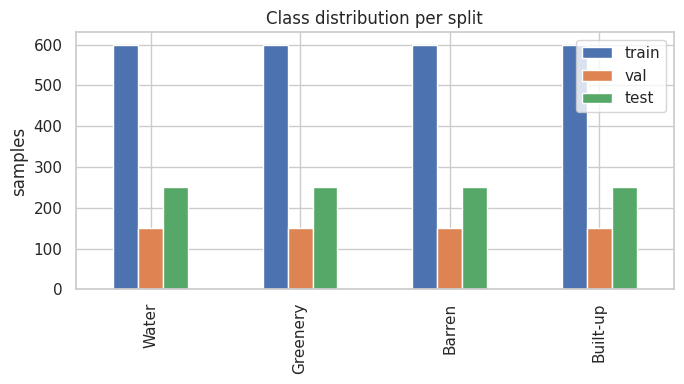

XGBoost                      acc=0.9490  macroF1=0.9492  kappa=0.9320  train=1.3s
LightGBM                     acc=0.9440  macroF1=0.9442  kappa=0.9253  train=0.7s

##### ResNet-1D
trained 17 epochs, 106,276 params
ResNet-1D                    acc=0.9400  macroF1=0.9403  kappa=0.9200  train=21.3s
XGBoost + ResNet-1D          acc=0.9400  macroF1=0.9404  kappa=0.9200  train=24.0s

##### EfficientNet-1D
trained 28 epochs, 79,464 params
EfficientNet-1D              acc=0.9590  macroF1=0.9591  kappa=0.9453  train=50.4s
XGBoost + EfficientNet-1D    acc=0.9560  macroF1=0.9562  kappa=0.9413  train=56.8s
LightGBM + EfficientNet-1D   acc=0.9600  macroF1=0.9602  kappa=0.9467  train=54.0s

=== TEST RESULTS (real) | test samples = 1000 ===
                             Accuracy  Precision  Recall      F1   Kappa  TrainTime  InferTime  InferMs_per_sample
Model                                                                                                            
XGBoost                        0.9

<Figure size 640x480 with 0 Axes>

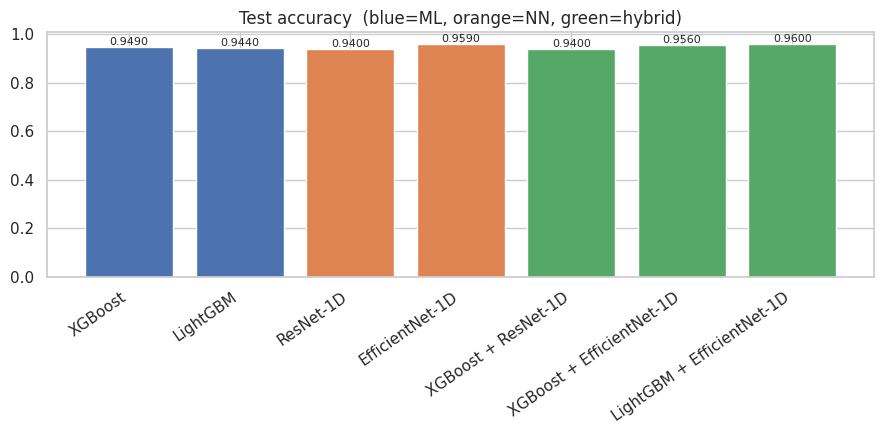

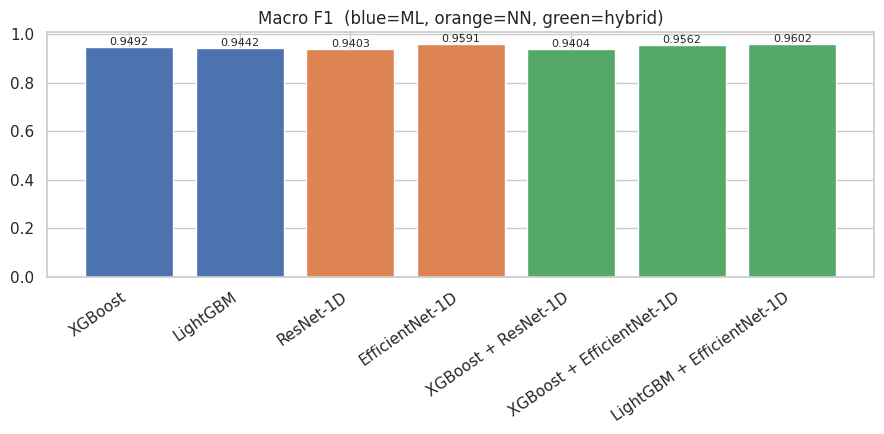

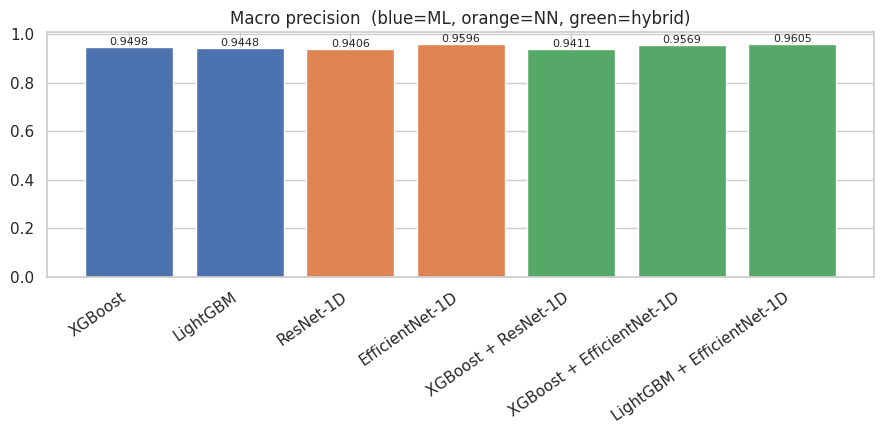

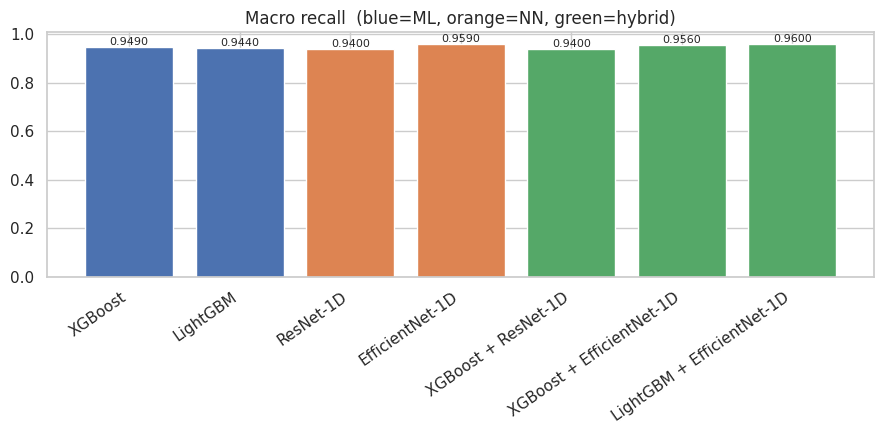

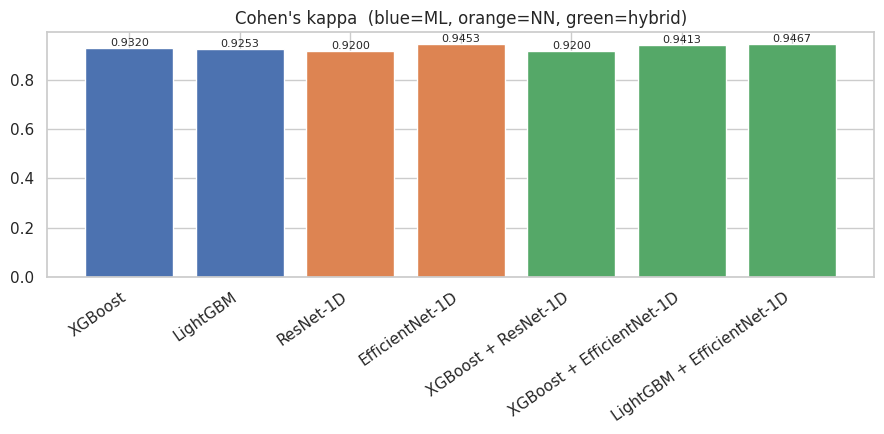

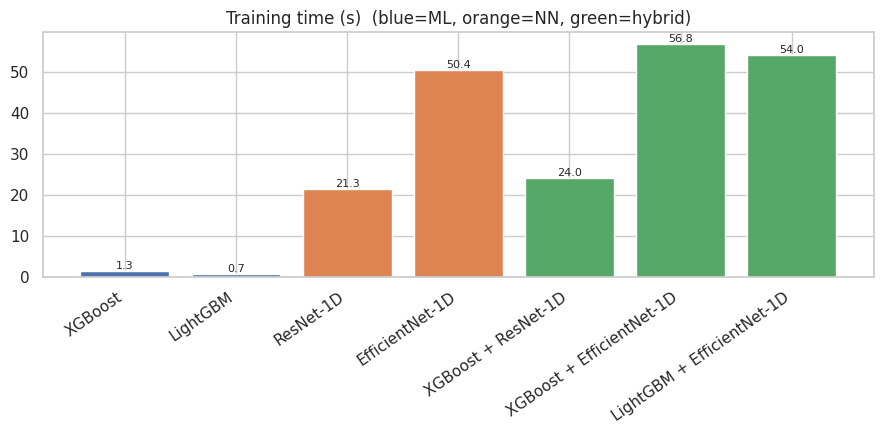

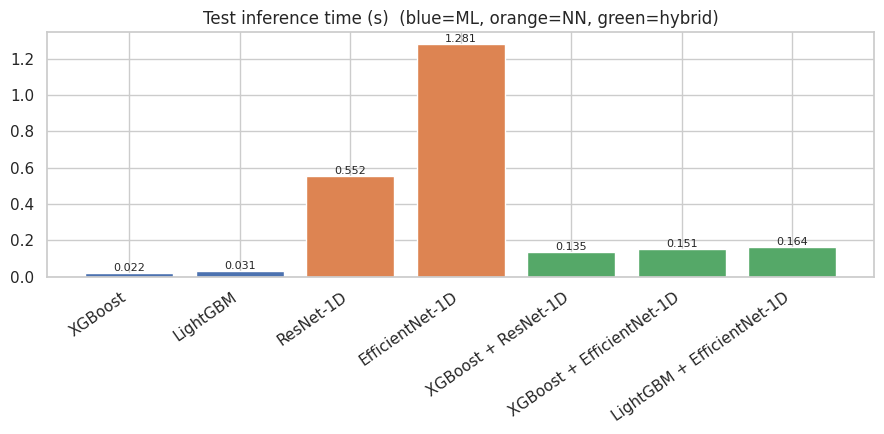

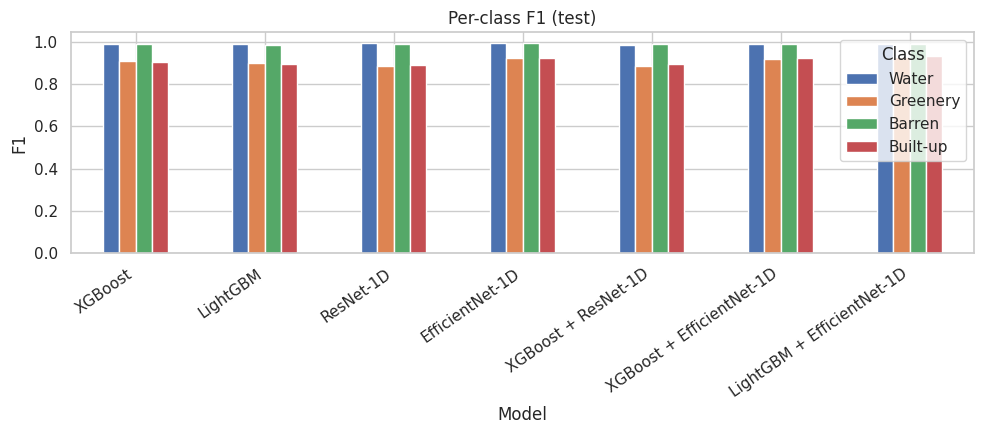

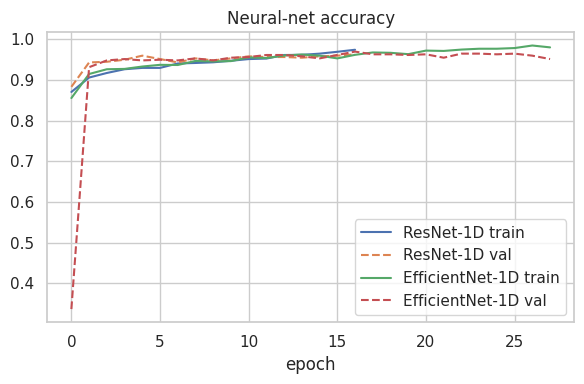

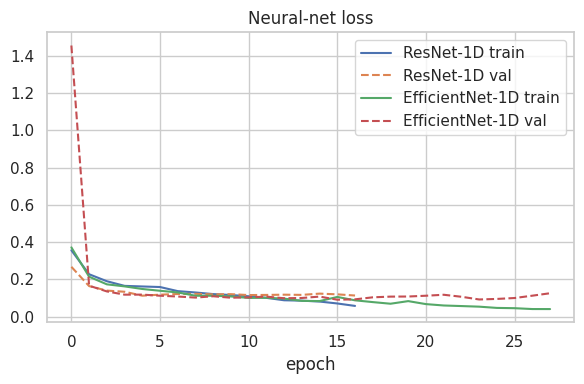

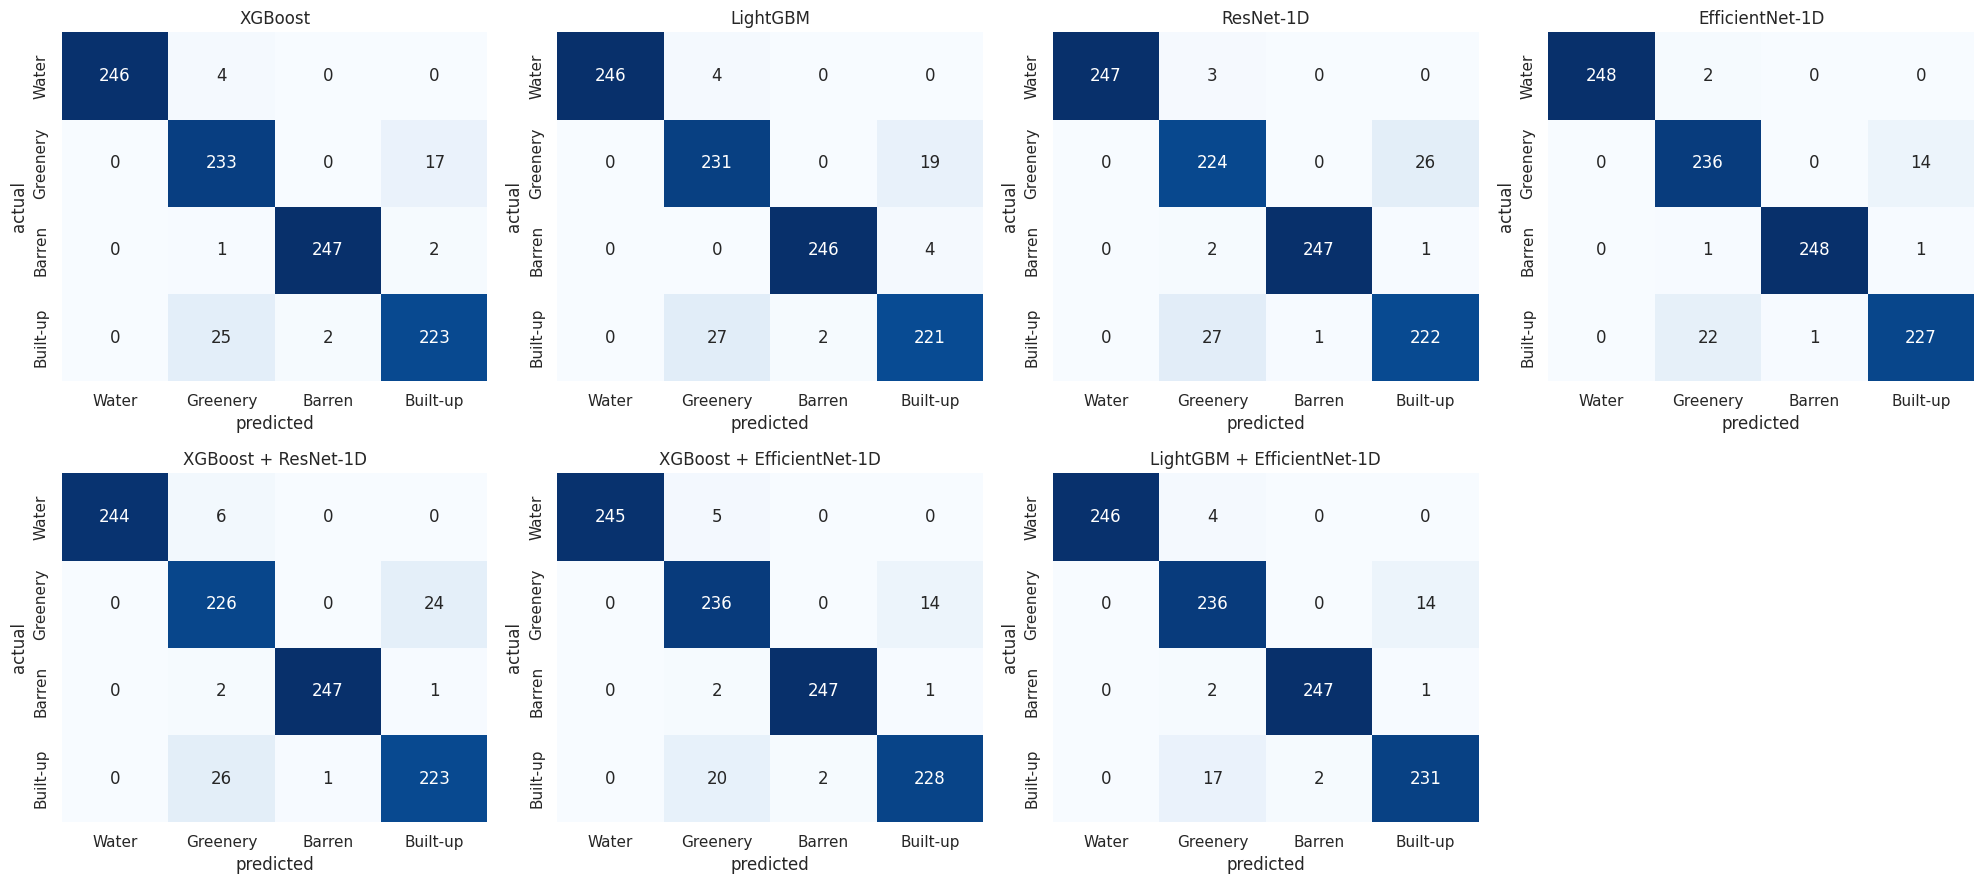

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =====================================================================
# GeoXNet Nanded (tabular Sentinel-2 pixels) -- 7 models, same split, real metrics
#   XGBoost | LightGBM | ResNet-1D | EfficientNet-1D
#   XGBoost + ResNet-1D | XGBoost + EfficientNet-1D | LightGBM + EfficientNet-1D
# IMPORTANT: the CSV has only per-pixel band values (no coordinates, no image patches),
# so "ResNet" / "EfficientNet" here are 1D spectral networks (ResNet-style / EfficientNet-style
# MBConv blocks) trained from scratch -- NOT the 2D ImageNet ResNet50 / EfficientNetB0.
# Run cell by cell in Colab (GPU optional). Cells are separated by "# %%".
# =====================================================================

# %% [1] Install + imports + config
# !pip -q install xgboost lightgbm seaborn
import os, time, json, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, cohen_kappa_score,
                             classification_report, confusion_matrix)
from xgboost import XGBClassifier
import lightgbm as lgb
import tensorflow as tf
from tensorflow.keras import layers, Model
warnings.filterwarnings("ignore")

CFG = dict(
    FILE_PATH="/content/GeoXNet_Nanded_Test.csv",   # upload the CSV to Colab (or mount Drive)
    OUT="/content/outputs_gbm", SEED=42,
    FEATURES=["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12", "NDVI", "NDWI", "NDBI"],
    TARGET="landcover",
    CLASS_NAMES={1: "Water", 2: "Greenery", 3: "Barren", 4: "Built-up"},   # same mapping as your XGBoost sample
    TEST_SIZE=0.25, VAL_FRAC=0.15,        # val = 15% of all data, taken from the training part
    DROP_DUPLICATES=True,                 # exact duplicate rows would leak between train and test
    EPOCHS=80, BATCH=64, LR=1e-3, FEAT_DIM=64, N_BOOT=300,
)
os.makedirs(CFG["OUT"], exist_ok=True)
np.random.seed(CFG["SEED"]); tf.random.set_seed(CFG["SEED"])

# %% [2] Load + inspect + clean
df = pd.read_csv(CFG["FILE_PATH"])
print("shape:", df.shape); print("columns:", list(df.columns)); print("dtypes:\n", df.dtypes.to_string())
miss = [c for c in CFG["FEATURES"] + [CFG["TARGET"]] if c not in df.columns]
assert not miss, f"Missing columns: {miss}"
extra = [c for c in df.columns if c not in CFG["FEATURES"] + [CFG["TARGET"]]]
print("other columns (ignored):", extra)
print("missing values:\n", df[CFG["FEATURES"] + [CFG["TARGET"]]].isna().sum().to_string())
print("coordinate-like columns present:", [c for c in df.columns if c.lower() in ("lat", "lon", "latitude", "longitude", "x", "y", "geometry")] or "NONE -> spatial split is impossible")

X = df[CFG["FEATURES"]].apply(pd.to_numeric, errors="coerce"); y = pd.to_numeric(df[CFG["TARGET"]], errors="coerce")
valid = X.notna().all(axis=1) & y.notna(); X, y = X.loc[valid], y.loc[valid].astype(int)
if CFG["DROP_DUPLICATES"]:
    d = pd.concat([X, y], axis=1).duplicated(); print("duplicate rows dropped:", int(d.sum())); X, y = X[~d], y[~d]
print("\nclass distribution (original labels):\n", y.value_counts().sort_index().to_string())
assert set(y.unique()) <= set(CFG["CLASS_NAMES"]), "unexpected label values"
CLASSES = [CFG["CLASS_NAMES"][k] for k in sorted(CFG["CLASS_NAMES"])]; yv = (y - 1).values; Xv = X.values.astype(np.float32)

# %% [3] Split (stratified random -- no coordinates exist, so NOT spatially independent)
Xtr0, Xte, ytr0, yte = train_test_split(Xv, yv, test_size=CFG["TEST_SIZE"], random_state=CFG["SEED"], stratify=yv)
Xtr, Xva, ytr, yva = train_test_split(Xtr0, ytr0, test_size=CFG["VAL_FRAC"] / (1 - CFG["TEST_SIZE"]),
                                      random_state=CFG["SEED"], stratify=ytr0)
print(f"train {len(Xtr)} | val {len(Xva)} | test {len(Xte)}")
sc = StandardScaler().fit(Xtr)                                   # scaler fitted on TRAIN only (used by the neural nets)
S = lambda a: sc.transform(a).astype(np.float32)[..., None]      # (N, 13, 1) sequence for Conv1D
pd.DataFrame({n: np.bincount(v, minlength=4) for n, v in [("train", ytr), ("val", yva), ("test", yte)]}, index=CLASSES)\
  .plot.bar(figsize=(7, 4), title="Class distribution per split"); plt.ylabel("samples"); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/fig01_class_distribution.png", dpi=200); plt.show()

# %% [4] Helpers
def metrics(yt, yp):
    p, r, f, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    return dict(Accuracy=accuracy_score(yt, yp), Precision=p, Recall=r, F1=f, Kappa=cohen_kappa_score(yt, yp),
                CM=confusion_matrix(yt, yp, labels=range(4)),
                report=classification_report(yt, yp, labels=range(4), target_names=CLASSES, zero_division=0, output_dict=True))

def fit_xgb(Xa, ya, Xb, yb):
    m = XGBClassifier(objective="multi:softprob", n_estimators=600, learning_rate=0.05, max_depth=4, subsample=0.8,
                      colsample_bytree=0.8, eval_metric="mlogloss", early_stopping_rounds=40,
                      random_state=CFG["SEED"], n_jobs=-1, tree_method="hist")
    t = time.time(); m.fit(Xa, ya, sample_weight=compute_sample_weight("balanced", ya), eval_set=[(Xb, yb)], verbose=False)
    return m, time.time() - t

def fit_lgb(Xa, ya, Xb, yb):
    m = lgb.LGBMClassifier(objective="multiclass", n_estimators=600, learning_rate=0.05, num_leaves=31, subsample=0.8,
                           subsample_freq=1, colsample_bytree=0.8, class_weight="balanced", random_state=CFG["SEED"],
                           n_jobs=-1, verbose=-1)
    t = time.time(); m.fit(Xa, ya, eval_set=[(Xb, yb)], callbacks=[lgb.early_stopping(40, verbose=False)])
    return m, time.time() - t

def predict(m, A):
    t = time.time(); p = np.asarray(m.predict(A)).ravel().astype(int); return p, time.time() - t

# 1D ResNet: residual Conv1D blocks over the 13 spectral/index positions
def res_block(x, f):
    s = x
    h = layers.Conv1D(f, 3, padding="same", use_bias=False)(x); h = layers.BatchNormalization(momentum=0.9)(h); h = layers.ReLU()(h)
    h = layers.Conv1D(f, 3, padding="same", use_bias=False)(h); h = layers.BatchNormalization(momentum=0.9)(h)
    if s.shape[-1] != f: s = layers.Conv1D(f, 1, use_bias=False)(s)
    return layers.ReLU()(layers.Add()([h, s]))

def build_resnet1d(n_feat):
    i = layers.Input((n_feat, 1)); x = layers.Conv1D(32, 3, padding="same", use_bias=False)(i)
    x = layers.ReLU()(layers.BatchNormalization(momentum=0.9)(x))
    for f in (32, 64, 64): x = res_block(x, f)
    return i, layers.Flatten()(x)

# 1D EfficientNet-style: MBConv (expand -> depthwise -> squeeze-excite -> project) with swish
def mbconv(x, out, exp=4, k=3):
    c = x.shape[-1]; e = c * exp
    h = layers.Conv1D(e, 1, use_bias=False)(x); h = layers.Activation("swish")(layers.BatchNormalization(momentum=0.9)(h))
    h = layers.DepthwiseConv1D(k, padding="same", use_bias=False)(h); h = layers.Activation("swish")(layers.BatchNormalization(momentum=0.9)(h))
    se = layers.GlobalAveragePooling1D()(h); se = layers.Dense(max(2, c // 4), activation="swish")(se)
    se = layers.Dense(e, activation="sigmoid")(se); h = layers.Multiply()([h, layers.Reshape((1, e))(se)])
    h = layers.BatchNormalization(momentum=0.9)(layers.Conv1D(out, 1, use_bias=False)(h))
    return layers.Add()([x, h]) if c == out else h

def build_effnet1d(n_feat):
    i = layers.Input((n_feat, 1)); x = layers.Conv1D(16, 3, padding="same", use_bias=False)(i)
    x = layers.Activation("swish")(layers.BatchNormalization(momentum=0.9)(x))
    for o in (16, 24, 24, 40): x = mbconv(x, o)
    x = layers.Activation("swish")(layers.BatchNormalization(momentum=0.9)(layers.Conv1D(64, 1, use_bias=False)(x)))
    return i, layers.Flatten()(x)

def build_net(kind):
    i, x = (build_resnet1d if kind == "ResNet-1D" else build_effnet1d)(Xtr.shape[1])
    x = layers.Dense(CFG["FEAT_DIM"], activation="relu", name="feat")(x); x = layers.Dropout(0.3)(x)
    m = Model(i, layers.Dense(4, activation="softmax")(x))
    m.compile(optimizer=tf.keras.optimizers.Adam(CFG["LR"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"]); return m

R, PRED, HIST = {}, {}, {}
def store(name, p, tr_t, inf_t):
    R[name] = dict(**metrics(yte, p), TrainTime=tr_t, InferTime=inf_t); PRED[name] = p
    print(f"{name:28s} acc={R[name]['Accuracy']:.4f}  macroF1={R[name]['F1']:.4f}  kappa={R[name]['Kappa']:.4f}  train={tr_t:.1f}s")

# %% [5] Tabular models on raw features: XGBoost, LightGBM
for name, fn in [("XGBoost", fit_xgb), ("LightGBM", fit_lgb)]:
    m, tt = fn(Xtr, ytr, Xva, yva); p, it = predict(m, Xte); store(name, p, tt, it)
    if name == "XGBoost": m.save_model(f"{CFG['OUT']}/xgboost.json")
    else: m.booster_.save_model(f"{CFG['OUT']}/lightgbm.txt")

# %% [6] 1D ResNet / 1D EfficientNet, then hybrids (NN feature vector + raw features -> XGBoost / LightGBM)
cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(4), y=ytr)))
HYB = {"ResNet-1D": [("XGBoost", fit_xgb)], "EfficientNet-1D": [("XGBoost", fit_xgb), ("LightGBM", fit_lgb)]}
for kind in ["ResNet-1D", "EfficientNet-1D"]:
    print(f"\n##### {kind}"); tf.keras.backend.clear_session(); net = build_net(kind)
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]
    t = time.time()
    h = net.fit(S(Xtr), ytr, validation_data=(S(Xva), yva), epochs=CFG["EPOCHS"], batch_size=CFG["BATCH"],
                class_weight=cw, callbacks=cbs, verbose=0)
    t_nn = time.time() - t; HIST[kind] = h.history; print(f"trained {len(h.history['loss'])} epochs, {net.count_params():,} params")
    t = time.time(); pn = net.predict(S(Xte), batch_size=512, verbose=0).argmax(1); it_nn = time.time() - t
    store(kind, pn, t_nn, it_nn); net.save(f"{CFG['OUT']}/{kind}.keras")
    fx = Model(net.input, net.get_layer("feat").output)
    t = time.time(); Ftr, Fva = fx.predict(S(Xtr), batch_size=512, verbose=0), fx.predict(S(Xva), batch_size=512, verbose=0); t_ext = time.time() - t
    Ztr, Zva = np.hstack([Ftr, Xtr]), np.hstack([Fva, Xva])
    for cname, fn in HYB[kind]:
        m, tt = fn(Ztr, ytr, Zva, yva)
        t = time.time(); Zte = np.hstack([fx.predict(S(Xte), batch_size=512, verbose=0), Xte])
        p = np.asarray(m.predict(Zte)).ravel().astype(int); it = time.time() - t       # extraction + classifier
        store(f"{cname} + {kind}", p, t_nn + t_ext + tt, it)

# %% [7] Results table, per-class reports, confusion matrices
order = ["XGBoost", "LightGBM", "ResNet-1D", "EfficientNet-1D",
         "XGBoost + ResNet-1D", "XGBoost + EfficientNet-1D", "LightGBM + EfficientNet-1D"]
T = pd.DataFrame([dict(Model=k, **{c: R[k][c] for c in ["Accuracy", "Precision", "Recall", "F1", "Kappa", "TrainTime", "InferTime"]})
                  for k in order]).set_index("Model")
T["InferMs_per_sample"] = T["InferTime"] / len(yte) * 1000
pd.set_option("display.width", 220)
print(f"\n=== TEST RESULTS (real) | test samples = {len(yte)} ===\n", T.round(4).to_string()); T.round(5).to_csv(f"{CFG['OUT']}/results.csv")
rows = []
for k in order:
    print(f"\n--- {k}\nConfusion matrix (rows=actual, cols=predicted; {CLASSES})\n{R[k]['CM']}")
    print(classification_report(yte, PRED[k], labels=range(4), target_names=CLASSES, zero_division=0, digits=4))
    for c in CLASSES: rows.append(dict(Model=k, Class=c, **{q: R[k]["report"][c][q] for q in ["precision", "recall", "f1-score", "support"]}))
    pd.DataFrame({"actual": yte + 1, "predicted": PRED[k] + 1}).to_csv(f"{CFG['OUT']}/pred_{k.replace(' ', '_').replace('+', 'plus')}.csv", index=False)
PC = pd.DataFrame(rows); PC.round(5).to_csv(f"{CFG['OUT']}/per_class_results.csv", index=False)
json.dump({k: R[k]["CM"].tolist() for k in order}, open(f"{CFG['OUT']}/confusion_matrices.json", "w"))

# %% [8] Does fusion help? paired bootstrap over test rows (rows may be spatially correlated -> indicative only)
def mf1(a, b): return precision_recall_fscore_support(a, b, average="macro", zero_division=0)[2]
rng = np.random.default_rng(0); n = len(yte); idx = [rng.integers(0, n, n) for _ in range(CFG["N_BOOT"])]
pairs = [("XGBoost + ResNet-1D", "XGBoost"), ("XGBoost + ResNet-1D", "ResNet-1D"),
         ("XGBoost + EfficientNet-1D", "XGBoost"), ("XGBoost + EfficientNet-1D", "EfficientNet-1D"),
         ("LightGBM + EfficientNet-1D", "LightGBM"), ("LightGBM + EfficientNet-1D", "EfficientNet-1D")]
dd = []
for a, b in pairs:
    d = np.array([mf1(yte[i], PRED[a][i]) - mf1(yte[i], PRED[b][i]) for i in idx]); lo, hi = np.percentile(d, [2.5, 97.5])
    dd.append(dict(hybrid=a, vs=b, dMacroF1=mf1(yte, PRED[a]) - mf1(yte, PRED[b]), CI_low=lo, CI_high=hi, CI_excludes_0=bool(lo > 0 or hi < 0)))
DD = pd.DataFrame(dd); print("\n=== Hybrid minus component (macro-F1, 95% bootstrap CI) ===\n", DD.round(4).to_string(index=False))
DD.round(5).to_csv(f"{CFG['OUT']}/hybrid_vs_component.csv", index=False)

# %% [9] Graphs (PNG)
sns.set_theme(style="whitegrid"); col = ["#4C72B0"] * 2 + ["#DD8452"] * 2 + ["#55A868"] * 3
def bar(s, fn, title, fmt="{:.4f}"):
    plt.figure(figsize=(9, 4.5)); plt.bar(range(len(s)), s.values, color=col)
    for i, v in enumerate(s.values): plt.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=8)
    plt.xticks(range(len(s)), s.index, rotation=35, ha="right"); plt.title(title + "  (blue=ML, orange=NN, green=hybrid)"); plt.tight_layout()
    plt.savefig(f"{CFG['OUT']}/{fn}", dpi=200); plt.show()
lo_acc = max(0, T.Accuracy.min() - 0.03)
plt.figure(); bar(T.Accuracy, "fig02_accuracy.png", "Test accuracy")
bar(T.F1, "fig03_macro_f1.png", "Macro F1"); bar(T.Precision, "fig03b_macro_precision.png", "Macro precision")
bar(T.Recall, "fig03c_macro_recall.png", "Macro recall"); bar(T.Kappa, "fig04_kappa.png", "Cohen's kappa")
bar(T.TrainTime, "fig05_train_time.png", "Training time (s)", "{:.1f}"); bar(T.InferTime, "fig06_inference_time.png", "Test inference time (s)", "{:.3f}")
pf = PC.pivot(index="Model", columns="Class", values="f1-score").loc[order][CLASSES]
pf.plot.bar(figsize=(10, 4.5)); plt.ylabel("F1"); plt.title("Per-class F1 (test)"); plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(f"{CFG['OUT']}/fig07_per_class_f1.png", dpi=200); plt.show()
for key, fn in [("accuracy", "fig08_nn_accuracy.png"), ("loss", "fig09_nn_loss.png")]:
    plt.figure(figsize=(6, 4))
    for k, h in HIST.items(): plt.plot(h[key], label=f"{k} train"); plt.plot(h["val_" + key], "--", label=f"{k} val")
    plt.title(f"Neural-net {key}"); plt.xlabel("epoch"); plt.legend(); plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/{fn}", dpi=200); plt.show()
fig, axs = plt.subplots(2, 4, figsize=(20, 9))
for a, k in zip(axs.ravel(), order):
    sns.heatmap(R[k]["CM"], annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set_title(k); a.set_xlabel("predicted"); a.set_ylabel("actual")
axs.ravel()[-1].axis("off"); plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/fig10_confusion_matrices.png", dpi=200); plt.show()

# %% [10] Zip outputs
import shutil; shutil.make_archive("/content/geoxnet_gbm_results", "zip", CFG["OUT"])
try:
    from google.colab import files; files.download("/content/geoxnet_gbm_results.zip")
except Exception: print("Saved /content/geoxnet_gbm_results.zip")

# **Conclusion**

Average used for P/R/F1: weighted | test size per run: [1000]

=== Table 4.3 (combined) ===
 Batch                      Model   Acc   Prec   Rec     F1  Kappa  Train_s  Infer_ms_per_sample  n_test
    A            EfficientNet-1D 0.959 0.9596 0.959 0.9591 0.9453  50.3751               1.2806    1000
    A                   LightGBM 0.944 0.9448 0.944 0.9442 0.9253   0.7016               0.0309    1000
    A LightGBM + EfficientNet-1D 0.960 0.9605 0.960 0.9602 0.9467  54.0276               0.1636    1000
    A                  ResNet-1D 0.940 0.9406 0.940 0.9403 0.9200  21.2988               0.5516    1000
    A                    XGBoost 0.949 0.9498 0.949 0.9492 0.9320   1.2744               0.0217    1000
    A  XGBoost + EfficientNet-1D 0.956 0.9569 0.956 0.9562 0.9413  56.8365               0.1512    1000
    A        XGBoost + ResNet-1D 0.940 0.9411 0.940 0.9404 0.9200  24.0301               0.1349    1000
    B                   CatBoost 0.948 0.9490 0.948 0.9483 0.9307  15.4700 

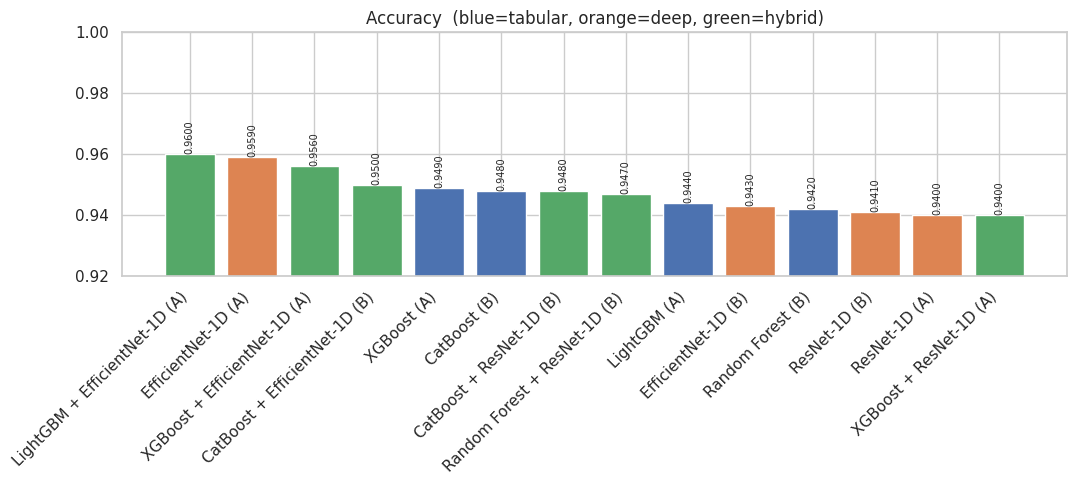

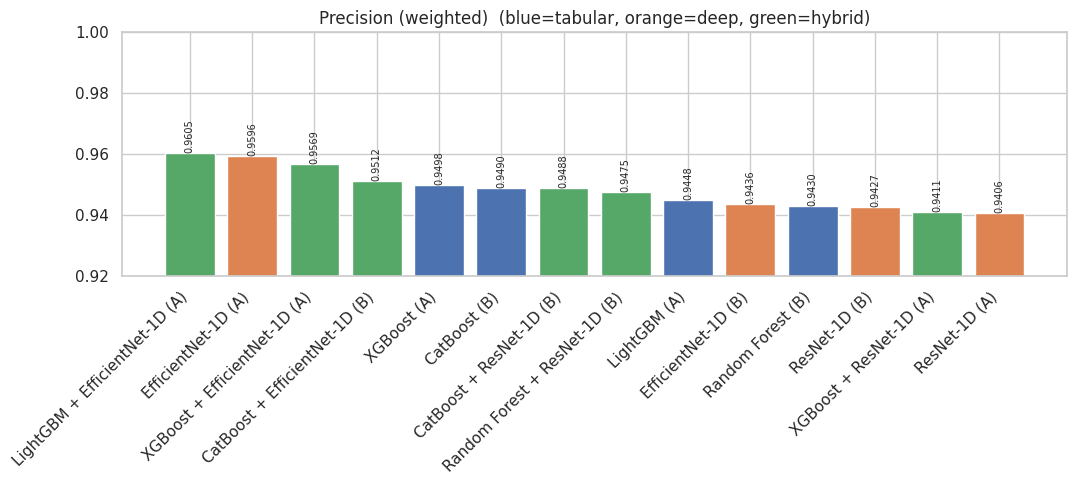

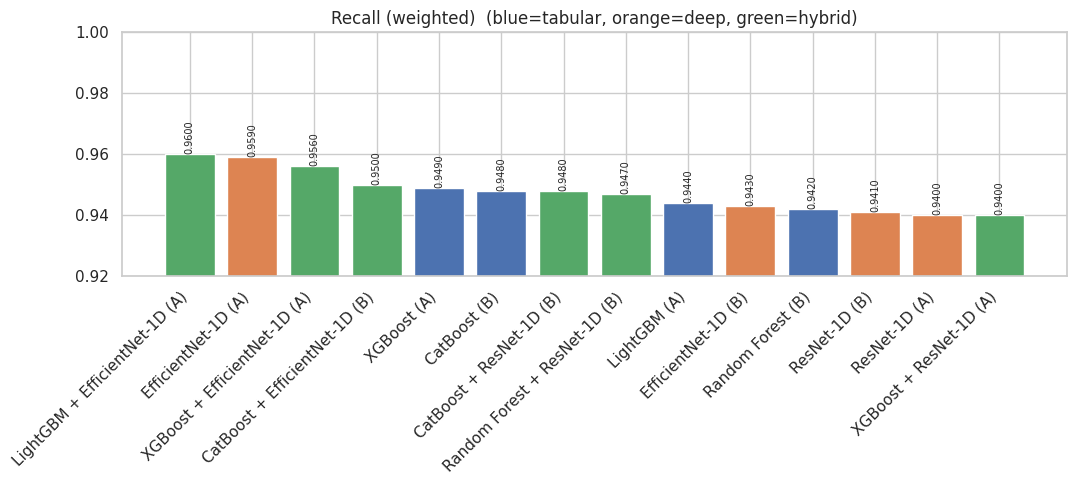

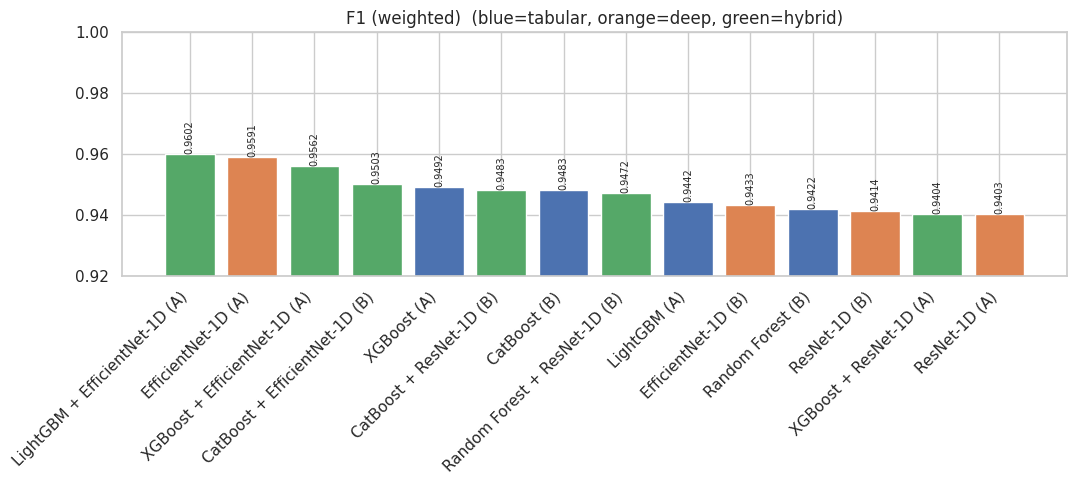

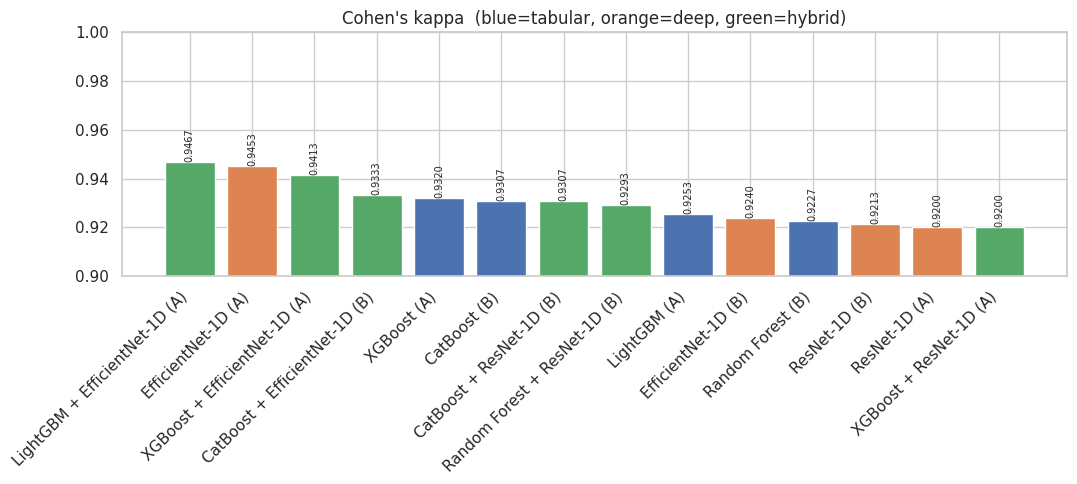

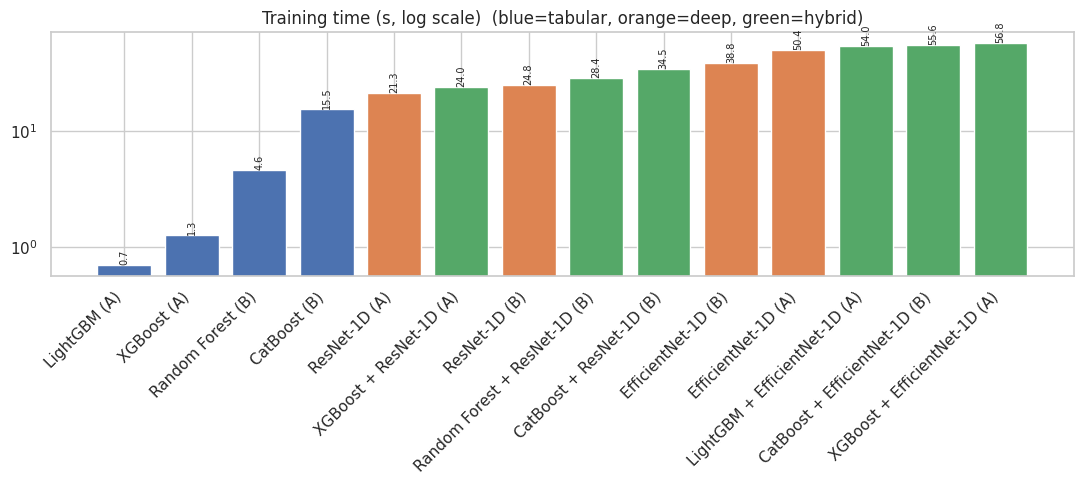

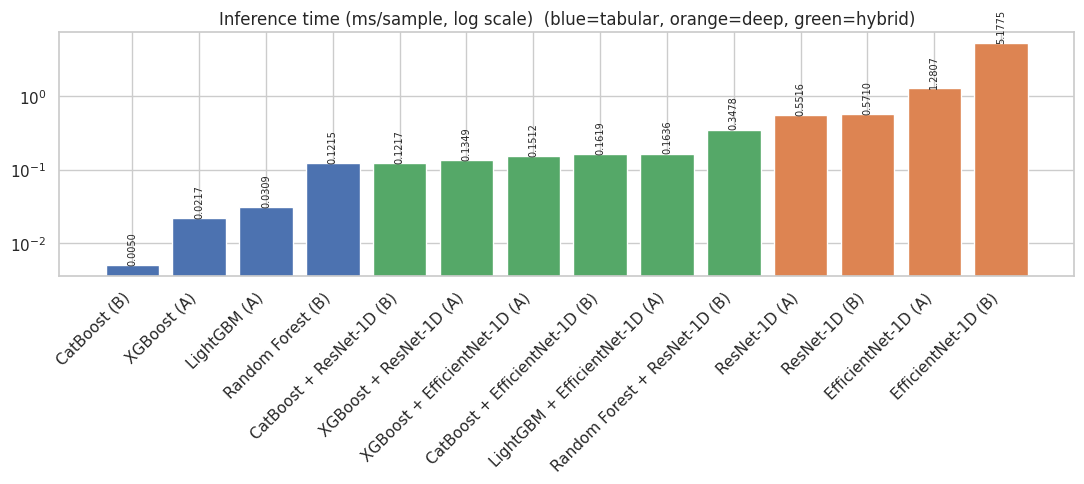

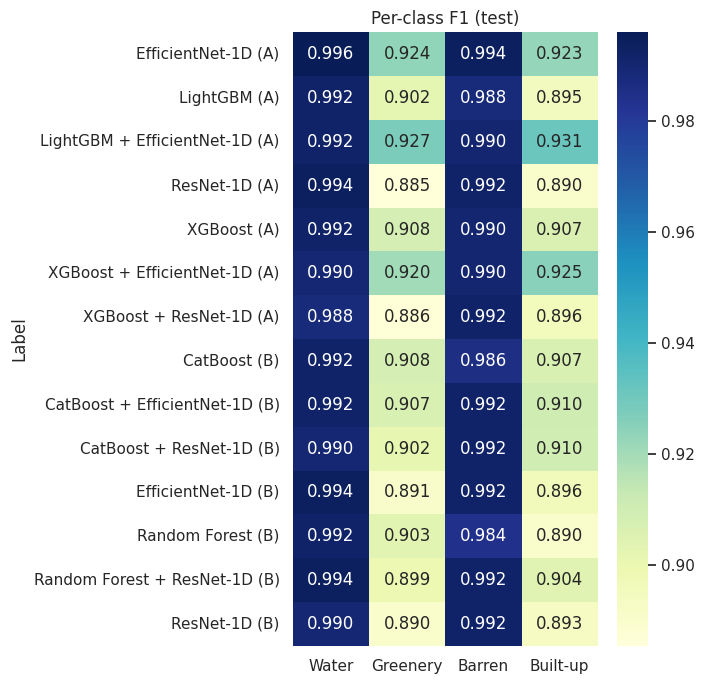

Saved to /content/combined


In [ ]:
# =====================================================================
# Merge the two Colab runs (XGBoost/LightGBM run + RF/CatBoost run) into ONE set of
# paper-ready tables and figures (14 rows), computed from the saved prediction files.
# Run in Colab AFTER both experiment scripts have finished.
# =====================================================================
import os, glob, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score

RUNS = {"A": "/content/outputs_gbm",   # run with XGBoost / LightGBM  (your "Batch A")
        "B": "/content/outputs"}       # run with Random Forest / CatBoost (your "Batch B")
AVERAGE = "weighted"                   # "weighted" (as written in your Section 4.3) or "macro"
OUT = "/content/combined"; os.makedirs(OUT, exist_ok=True)
CLASSES = ["Water", "Greenery", "Barren", "Built-up"]

rows, perclass = [], []
for batch, d in RUNS.items():
    timing = pd.read_csv(f"{d}/results.csv", index_col="Model")
    for f in sorted(glob.glob(f"{d}/pred_*.csv")):
        name = os.path.basename(f)[5:-4].replace("_plus_", " + ").replace("_", " ")
        p = pd.read_csv(f); yt, yp = p.actual.values, p.predicted.values
        pr, rc, f1, _ = precision_recall_fscore_support(yt, yp, average=AVERAGE, zero_division=0)
        rows.append(dict(Batch=batch, Model=name, Acc=accuracy_score(yt, yp), Prec=pr, Rec=rc, F1=f1,
                         Kappa=cohen_kappa_score(yt, yp), Train_s=timing.loc[name, "TrainTime"],
                         Infer_ms_per_sample=timing.loc[name, "InferTime"] / len(yt) * 1000, n_test=len(yt)))
        _, _, pf, _ = precision_recall_fscore_support(yt, yp, labels=[1, 2, 3, 4], zero_division=0)
        perclass.append(dict(Batch=batch, Model=name, **dict(zip(CLASSES, pf))))
T = pd.DataFrame(rows); PC = pd.DataFrame(perclass)
T["Label"] = T.Model + " (" + T.Batch + ")"
print(f"Average used for P/R/F1: {AVERAGE} | test size per run: {T.n_test.unique()}")
pd.set_option("display.width", 220); print("\n=== Table 4.3 (combined) ===\n", T.drop(columns="Label").round(4).to_string(index=False))
T.drop(columns="Label").round(5).to_csv(f"{OUT}/table_4_3_combined.csv", index=False); PC.round(5).to_csv(f"{OUT}/per_class_f1_combined.csv", index=False)

# ---- Table 4.4: ablation (tabular-only / deep-only / combined, same batch) ----
abl = []
for _, r in T[T.Model.str.contains(r" \+ ")].iterrows():
    tab, deep = [s.strip() for s in r.Model.split(" + ")]
    g = T[T.Batch == r.Batch].set_index("Model")
    if tab in g.index and deep in g.index:
        abl.append(dict(Batch=r.Batch, Hybrid=r.Model, Tabular=g.loc[tab, "Acc"], Deep=g.loc[deep, "Acc"], Combined=r.Acc,
                        d_vs_tab_pts=(r.Acc - g.loc[tab, "Acc"]) * 100, d_vs_deep_pts=(r.Acc - g.loc[deep, "Acc"]) * 100))
AB = pd.DataFrame(abl); print("\n=== Table 4.4 (ablation, accuracy) ===\n", AB.round(4).to_string(index=False)); AB.round(5).to_csv(f"{OUT}/table_4_4_ablation.csv", index=False)
fam = lambda m: "Hybrid" if " + " in m else ("Deep" if "1D" in m else "Tabular")
print("\nMean accuracy by family:\n", T.assign(Family=T.Model.map(fam)).groupby("Family").Acc.mean().round(4).to_string())

# ---- Figures (14 bars each) ----
sns.set_theme(style="whitegrid"); pal = {"Tabular": "#4C72B0", "Deep": "#DD8452", "Hybrid": "#55A868"}
def bar(col, fn, title, fmt="{:.4f}", log=False, ylim=None):
    s = T.sort_values(col, ascending=log); plt.figure(figsize=(11, 5))
    ax = plt.bar(range(len(s)), s[col], color=[pal[fam(m)] for m in s.Model])
    for i, v in enumerate(s[col]): plt.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=7, rotation=90)
    plt.xticks(range(len(s)), s.Label, rotation=45, ha="right"); plt.title(title + "  (blue=tabular, orange=deep, green=hybrid)")
    if log: plt.yscale("log")
    if ylim: plt.ylim(*ylim)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fn}", dpi=200); plt.show()
lo = max(0, T.Acc.min() - 0.02)
bar("Acc", "fig_accuracy.png", "Accuracy", ylim=(lo, 1)); bar("Prec", "fig_precision.png", f"Precision ({AVERAGE})", ylim=(lo, 1))
bar("Rec", "fig_recall.png", f"Recall ({AVERAGE})", ylim=(lo, 1)); bar("F1", "fig_f1.png", f"F1 ({AVERAGE})", ylim=(lo, 1))
bar("Kappa", "fig_kappa.png", "Cohen's kappa", ylim=(max(0, T.Kappa.min() - 0.02), 1))
bar("Train_s", "fig_train_time.png", "Training time (s, log scale)", "{:.1f}", log=True)
bar("Infer_ms_per_sample", "fig_inference_time.png", "Inference time (ms/sample, log scale)", "{:.4f}", log=True)
H = PC.assign(Label=PC.Model + " (" + PC.Batch + ")").set_index("Label")[CLASSES]
plt.figure(figsize=(7, 7)); sns.heatmap(H, annot=True, fmt=".3f", cmap="YlGnBu"); plt.title("Per-class F1 (test)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_per_class_f1.png", dpi=200); plt.show(); print("Saved to", OUT)